# Selection refinement 3 — volatility-regime gross scaling (a NULL)

**Question.** Should the book de-risk when *market* volatility is high?

**Hypothesis.** Carry strategies are often said to "pick up pennies in front of a steamroller" — to pay
steadily then draw down in turbulent regimes. If so, scaling gross exposure down when BTC realized vol
is high should improve risk-adjusted return.

**Method.** Regime = **expanding point-in-time percentile** of BTC 30d realized vol (from 1h spot bars).
Exposure multiplier: **1.0 below p70**, ramping linearly down to a **floor above p90** (try floor = 0.5
and 0.0). Apply the multiplier to the v3.1 book (`W *= exposure`, causal). Then the key cross-check: does
this overlap the **v4 drawdown overlay** (which de-risks on the *shadow book's own* drawdown)? Correlate
the two exposure series — if they mostly overlap, the overlay already captures it; if they don't, we
learn whether vol is even the right signal. All booked via `lab.py` (engine parity 1e-6).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
from src.data import query
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS = cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
maj, non = H.universe(); P = H.load_panels(maj + non)
F, E, didx, syms = P['F'], P['E'], P['didx'], P['symbols']
SPECS = [{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO  = [{'feature':'funding_vol','direction':'max','cap':0.75},
         {'feature':'neg_freq','direction':'max','cap':0.40},
         {'feature':'basis','direction':'max','cap':0.01}]
# v3.1 book (unchanged), via lab.evaluate_select — the object we will scale
V31 = H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,
                        size_kind='inv_basis_vol',band=0.5,warmup_days=30)
Wsh = V31['W']
def kpi(res):
    a,b = res['1.0x'], res['2.0x']
    return {'net%':round(a['ann_return']*100,2),'Sharpe':round(a['sharpe'],2),
            'net@2x%':round(b['ann_return']*100,2),'Sh@2x':round(b['sharpe'],2),
            'maxDD%':round(a['max_drawdown']*100,2),'Calmar':round(a['ann_return']/abs(a['max_drawdown']),1),
            'turn':round(a['ann_turnover'],1)}
def eq(res): return res['net'].cumsum()*100
base = H.book(Wsh, P, COSTS, warmup_days=30)
print('v3.1 baseline:', kpi(base))

# BTC 30d realized vol from 1h spot bars, expanding point-in-time percentile
btc = query.get('spot','binance','btcusdt','bars',timeframe='1h',start='2021-01-01',end='2026-05-31')
r1h = np.log(btc['close']).diff()
rv = (r1h.rolling(30*24, min_periods=15*24).std() * np.sqrt(24*365))
rv_d = rv.resample('1D').last().reindex(didx)
pct = rv_d.expanding(min_periods=120).apply(lambda s: (s.iloc[-1] >= s).mean(), raw=False)   # causal percentile
print(f'BTC 30d realized vol: median {rv_d.median()*100:.0f}%  p70 {rv_d.quantile(0.7)*100:.0f}%  p90 {rv_d.quantile(0.9)*100:.0f}%')

v3.1 baseline: {'net%': 9.94, 'Sharpe': 6.32, 'net@2x%': 6.05, 'Sh@2x': 3.62, 'maxDD%': -2.8, 'Calmar': 3.5, 'turn': 20.5}
BTC 30d realized vol: median 52%  p70 62%  p90 80%


## 1. The vol regime and the exposure multiplier

BTC 30d realized vol with its expanding point-in-time percentile, and the exposure multiplier it
implies (1.0 below p70, ramping to the floor above p90). Note *when* it throttles: the big high-vol
episodes are mid-2021 (bull run) and the 2022 unwind. Keep an eye on whether those are when the carry
actually suffers.

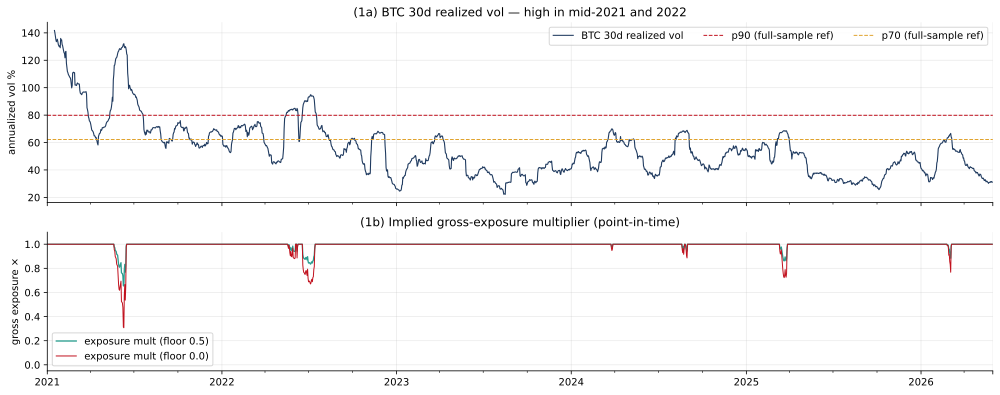

In [2]:
def regime_exp(floor):
    ramp = (1.0 - (pct-0.70)/0.20*(1.0-floor)).clip(floor,1.0)
    e = pd.Series(1.0, index=didx).where(pct<=0.70, ramp).where(pct<0.90, floor)
    return e.where(pct.notna(), 1.0)
exp05, exp00 = regime_exp(0.5), regime_exp(0.0)
fig,(a1,a2) = plt.subplots(2,1,figsize=(14,5.6),sharex=True,gridspec_kw={'height_ratios':[1.3,1]})
(rv_d*100).plot(ax=a1,color=NAVY,lw=1.1,label='BTC 30d realized vol')
a1.axhline(rv_d.quantile(0.9)*100,color=RED,ls='--',lw=1,label='p90 (full-sample ref)')
a1.axhline(rv_d.quantile(0.7)*100,color=AMBER,ls='--',lw=1,label='p70 (full-sample ref)')
a1.set_ylabel('annualized vol %'); a1.legend(ncol=3); a1.set_title('(1a) BTC 30d realized vol — high in mid-2021 and 2022')
exp05.plot(ax=a2,color=TEAL,lw=1.3,label='exposure mult (floor 0.5)')
exp00.plot(ax=a2,color=RED,lw=1.0,label='exposure mult (floor 0.0)')
a2.set_ylabel('gross exposure ×'); a2.set_ylim(-0.05,1.1); a2.legend(); a2.set_title('(1b) Implied gross-exposure multiplier (point-in-time)')
plt.tight_layout(); plt.show()

## 2. Scaling by vol regime does not help

Book v3.1 with the multiplier applied. Both floors leave net Sharpe, 2×-cost Sharpe, and maxDD
essentially unchanged (a touch *worse*) — in-sample and on the 2024-2026 test window. The throttling
does not line up with the book's bad periods, so it just shaves return without cutting risk.

                      IS net%  IS Sh  IS 2x  IS maxDD%  TEST Sh  TEST 2x  TEST DD%
v3.1 (no scaling)        9.94   6.32   3.62      -2.80     7.52     4.32     -0.56
vol-regime floor 0.5     9.89   6.31   3.60      -2.84     7.52     4.31     -0.55
vol-regime floor 0.0     9.82   6.28   3.54      -2.88     7.47     4.20     -0.60


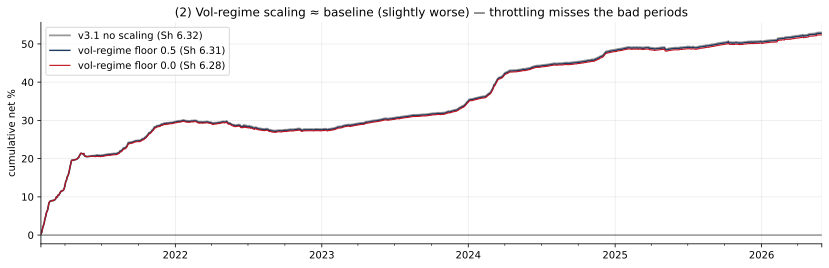

In [3]:
tr = H._window_mask(didx, end='2023-12-31'); te = H._window_mask(didx, start='2024-01-01')
def scaled(exp, mask=None): return H.book(Wsh.mul(exp,axis=0), P, COSTS, mask=mask, warmup_days=30)
def three(exp):
    full=scaled(exp); tst=scaled(exp,te)
    return {'IS net%':kpi(full)['net%'],'IS Sh':kpi(full)['Sharpe'],'IS 2x':kpi(full)['Sh@2x'],'IS maxDD%':kpi(full)['maxDD%'],
            'TEST Sh':round(tst['1.0x']['sharpe'],2),'TEST 2x':round(tst['2.0x']['sharpe'],2),'TEST DD%':round(tst['1.0x']['max_drawdown']*100,2)}
tab = {'v3.1 (no scaling)':three(pd.Series(1.0,index=didx)),
       'vol-regime floor 0.5':three(exp05),'vol-regime floor 0.0':three(exp00)}
print(pd.DataFrame(tab).T.to_string())
r05 = scaled(exp05)
fig,ax = plt.subplots(figsize=(14,4))
eq(base).plot(ax=ax,color=GREY,lw=1.8,label=f"v3.1 no scaling (Sh {base['1.0x']['sharpe']:.2f})")
eq(r05).plot(ax=ax,color=NAVY,lw=1.4,label=f"vol-regime floor 0.5 (Sh {r05['1.0x']['sharpe']:.2f})")
eq(scaled(exp00)).plot(ax=ax,color=RED,lw=1.1,label=f"vol-regime floor 0.0 (Sh {scaled(exp00)['1.0x']['sharpe']:.2f})")
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %'); ax.legend()
ax.set_title('(2) Vol-regime scaling ≈ baseline (slightly worse) — throttling misses the bad periods'); plt.show()

## 3. Why it fails — vol regime is the *wrong* signal

Compare the vol-regime exposure to the **v4 drawdown overlay** (which de-risks on the shadow book's
*own* sustained drawdown). If they overlapped, the overlay would already subsume this idea. They don't:
the two exposure series are **nearly uncorrelated**, and when the vol scaler throttles (high BTC vol)
the overlay is essentially never out — the overlap is ~zero. The book's actual bad regime (the long,
shallow 2022 funding-compression drawdown) does **not** coincide with the realized-vol spikes.

corr(vol-regime, v4 overlay exposure) = 0.075
vol scaler throttling days: 107 | v4 overlay OUT days: 440 | days BOTH de-risk: 0


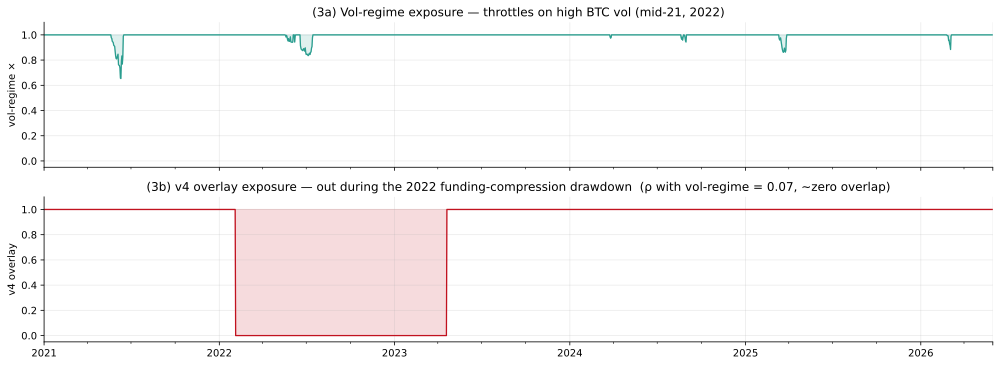

In [4]:
dd = H.drawdown(base['net'].reindex(didx))
ov = H.overlay_state(dd, qexit=0.15, qreenter=0.50, lookback=252, expanding=True)   # v4 exposure (0/1)
both = pd.concat([exp05.rename('vol-regime'), ov.rename('v4 overlay')],axis=1).dropna()
rho = both['vol-regime'].corr(both['v4 overlay'])
overlap = int(((exp05<0.75)&(ov<0.5)).sum()); voldays=int((exp05<1).sum()); ovdays=int((ov<0.5).sum())
print(f'corr(vol-regime, v4 overlay exposure) = {rho:.3f}')
print(f'vol scaler throttling days: {voldays} | v4 overlay OUT days: {ovdays} | days BOTH de-risk: {overlap}')
fig,(a1,a2)=plt.subplots(2,1,figsize=(14,5.2),sharex=True)
exp05.plot(ax=a1,color=TEAL,lw=1.3); a1.fill_between(exp05.index,exp05,1.0,color=TEAL,alpha=0.15)
a1.set_ylabel('vol-regime ×'); a1.set_ylim(-0.05,1.1); a1.set_title(f'(3a) Vol-regime exposure — throttles on high BTC vol (mid-21, 2022)')
ov.plot(ax=a2,color=RED,lw=1.3); a2.fill_between(ov.index,ov,1.0,color=RED,alpha=0.15)
a2.set_ylabel('v4 overlay'); a2.set_ylim(-0.05,1.1); a2.set_title(f'(3b) v4 overlay exposure — out during the 2022 funding-compression drawdown  (ρ with vol-regime = {rho:.2f}, ~zero overlap)')
plt.tight_layout(); plt.show()

## Verdict — NULL

- **Vol-regime gross scaling does not improve v3.1** at either floor (0.5, 0.0), at 1× or 2× cost, in
  sample or out. Net Sharpe, 2×-cost Sharpe and maxDD are all essentially unchanged (a touch worse) —
  the multiplier shaves return without cutting risk.
- **Mechanism — it's the wrong conditioning variable.** A *delta-neutral* long-spot/short-perp book is
  largely insulated from directional volatility (the two legs move together). Its drawdown is a slow
  **funding-compression regime** (the 2022 episode), which is temporally *distinct* from realized-vol
  spikes: the vol-regime exposure and the v4 drawdown-overlay exposure are nearly uncorrelated
  (ρ≈0.07) with ~zero overlapping de-risk days. High BTC vol in mid-2021 coincided with *good* carry;
  the throttle fires then and gives up return for nothing.
- **Relationship to v4.** The overlay is *not* "already capturing" the vol regime — it captures a
  better, different signal (the book's own realized drawdown). Conditioning on carry P&L beats
  conditioning on market vol. No reason to add a vol-regime layer.
- **Caveat.** Tested one proxy (BTC 30d realized vol, expanding percentile, p70/p90 ramp). A different
  turbulence proxy (cross-sectional funding dispersion, basis-vol breadth) might condition better — but
  that is a *funding/basis* regime, i.e. what the v4 overlay already keys off indirectly. Directional
  price vol is the wrong axis.